# Customer Churn Prediction — Task D

AI Powered E-Commerce Customer Intelligence System

This notebook creates the churn dataset using customer purchase history through **31 May 2026**, defines churn using the **1 June 2026–31 August 2026** target window, compares **Logistic Regression** and **Random Forest**, evaluates both models, and saves the best model for the Streamlit application.

## 1. Hackathon churn definition

- Feature period: orders on or before **31 May 2026**.
- Target window: **1 June 2026 to 31 August 2026**.
- Eligible customers: customers with at least one purchase on or before 31 May 2026.
- `churn = 1`: no purchase during the target window.
- `churn = 0`: at least one purchase during the target window.

Features required by the brief: Total orders, Total spending, Average order value, Days since last order, Return rate, Average delivery days, Age, and Membership type.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    classification_report,
)
import joblib

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

In [2]:
# Locate the SQLite database relative to this notebook.
# Put this notebook in a folder where ../ecommerce_hackathon.db points to the database,
# or change DB_PATH manually if needed.

NOTEBOOK_DIR = Path.cwd()
possible_paths = [
    NOTEBOOK_DIR / 'ecommerce_hackathon.db',
    NOTEBOOK_DIR.parent / 'ecommerce_hackathon.db',
]

DB_PATH = next((p for p in possible_paths if p.exists()), None)

if DB_PATH is None:
    raise FileNotFoundError(
        'ecommerce_hackathon.db was not found. Put the database in the notebook folder '
        'or one folder above it, then run this cell again.'
    )

print('Database:', DB_PATH.resolve())

conn = sqlite3.connect(DB_PATH)
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;",
    conn
)
conn.close()

tables

Database: C:\Users\IQRA TRADERS\Desktop\hackaton\hackaton\ecommerce_hackathon.db


,name
0,customers
1,orders
2,products
3,reviews


In [3]:
# Inspect the required tables and their columns.

conn = sqlite3.connect(DB_PATH)

customers = pd.read_sql_query('SELECT * FROM customers;', conn)
orders = pd.read_sql_query('SELECT * FROM orders;', conn)

conn.close()

print('Customers shape:', customers.shape)
print('Orders shape:', orders.shape)

print('\nCustomers columns:')
print(customers.columns.tolist())

print('\nOrders columns:')
print(orders.columns.tolist())

Customers shape: (8000, 9)
Orders shape: (65000, 10)

Customers columns:
['customer_id', 'customer_name', 'age', 'gender', 'city', 'signup_date', 'membership_type', 'email', 'phone']

Orders columns:
['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days', 'returned']


## 2. Data preparation

Dates are converted to datetime and numeric transaction fields are converted to numeric values. We keep the original SQLite database unchanged and perform the modeling preparation in Pandas.

In [4]:
customers = customers.copy()
orders = orders.copy()

orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')
customers['age'] = pd.to_numeric(customers['age'], errors='coerce')
orders['quantity'] = pd.to_numeric(orders['quantity'], errors='coerce')
orders['unit_price'] = pd.to_numeric(orders['unit_price'], errors='coerce')
orders['discount'] = pd.to_numeric(orders['discount'], errors='coerce')
orders['delivery_days'] = pd.to_numeric(orders['delivery_days'], errors='coerce')

print('Missing order_date:', orders['order_date'].isna().sum())
print('Missing customer age:', customers['age'].isna().sum())
print('Missing quantity:', orders['quantity'].isna().sum())
print('Missing unit_price:', orders['unit_price'].isna().sum())
print('Missing discount:', orders['discount'].isna().sum())
print('Missing delivery_days:', orders['delivery_days'].isna().sum())

Missing order_date: 30
Missing customer age: 100
Missing quantity: 0
Missing unit_price: 0
Missing discount: 0
Missing delivery_days: 40


In [5]:
# Clean the fields needed for the churn calculation.
# Records without a valid customer, date, quantity, price, or discount cannot
# contribute safely to the transaction-based features.

orders_model = orders.dropna(
    subset=['customer_id', 'order_date', 'quantity', 'unit_price', 'discount']
).copy()

# The supplied discount values are decimal fractions (for example 0.10 = 10%).
orders_model['net_amount'] = (
    orders_model['quantity']
    * orders_model['unit_price']
    * (1 - orders_model['discount'])
)

# Normalize returned to a numeric 0/1 indicator for return-rate calculation.
returned_text = orders_model['returned'].astype(str).str.strip().str.lower()
orders_model['returned_flag'] = returned_text.isin(
    ['1', 'true', 'yes']
).astype(int)

print('Model-ready orders:', len(orders_model))
orders_model.head()

Model-ready orders: 64970


,order_id,customer_id,product_id,order_date,quantity,unit_price,discount,payment_method,delivery_days,returned,net_amount,returned_flag
0,1,2367,389,2026-04-30,1,398.2700,0.1080,Cash on Delivery,1.0000,0,355.2568,0
1,2,2038,927,2026-02-09,2,"44,488.2000",0.0840,Debit/Credit Card,1.0000,0,"81,502.3824",0
2,3,6285,909,2026-03-30,1,"4,719.9100",0.1250,Cash on Delivery,1.0000,0,"4,129.9212",0
3,4,3714,117,2026-03-24,1,"2,053.6400",0.1180,Easypaisa,4.0000,0,"1,811.3105",0
4,5,3021,733,2024-12-13,1,"31,378.7700",0.0870,Debit/Credit Card,2.0000,0,"28,648.8170",0


## 3. Create churn features without leakage

All customer features below are calculated only from orders dated **on or before 31 May 2026**. The target-window orders are used only to create the churn label.

In [6]:
FEATURE_CUTOFF = pd.Timestamp('2026-05-31')
TARGET_START = pd.Timestamp('2026-06-01')
TARGET_END = pd.Timestamp('2026-08-31')

feature_orders = orders_model[
    orders_model['order_date'] <= FEATURE_CUTOFF
].copy()

target_orders = orders_model[
    (orders_model['order_date'] >= TARGET_START)
    & (orders_model['order_date'] <= TARGET_END)
].copy()

print('Feature-period orders:', len(feature_orders))
print('Target-window orders:', len(target_orders))
print('Latest feature-period order:', feature_orders['order_date'].max())
print('Target-window latest order:', target_orders['order_date'].max())

Feature-period orders: 49706
Target-window orders: 15264
Latest feature-period order: 2026-05-31 00:00:00
Target-window latest order: 2026-08-31 00:00:00


In [7]:
# Customer-level purchase features through 31 May 2026.

customer_features = feature_orders.groupby('customer_id').agg(
    total_orders=('order_id', 'nunique'),
    total_spending=('net_amount', 'sum'),
    last_order_date=('order_date', 'max'),
    returned_orders=('returned_flag', 'sum'),
    average_delivery_days=('delivery_days', 'mean'),
).reset_index()

customer_features['average_order_value'] = (
    customer_features['total_spending']
    / customer_features['total_orders'].replace(0, np.nan)
)

customer_features['days_since_last_order'] = (
    FEATURE_CUTOFF - customer_features['last_order_date']
).dt.days

customer_features['return_rate'] = (
    customer_features['returned_orders']
    / customer_features['total_orders'].replace(0, np.nan)
)

customer_features.head()

,customer_id,total_orders,total_spending,last_order_date,returned_orders,average_delivery_days,average_order_value,days_since_last_order,return_rate
0,2,3,"6,229.4990",2026-05-28,0,4.6667,"2,076.4997",3,0.0000
1,3,6,"24,102.4621",2026-02-13,0,3.1667,"4,017.0770",107,0.0000
2,4,5,"14,400.8129",2026-05-18,0,3.0000,"2,880.1626",13,0.0000
3,5,8,"76,312.8067",2026-05-12,0,3.5000,"9,539.1008",19,0.0000
4,6,3,"50,020.1630",2025-03-17,0,3.0000,"16,673.3877",440,0.0000


In [8]:
# Create the churn target using only the future target window.

target_customer_ids = set(target_orders['customer_id'].dropna().unique())

customer_features['churn'] = (
    ~customer_features['customer_id'].isin(target_customer_ids)
).astype(int)

# Add customer profile features.
customer_model = customer_features.merge(
    customers[['customer_id', 'age', 'membership_type']],
    on='customer_id',
    how='left'
)

customer_model['membership_type'] = (
    customer_model['membership_type']
    .astype('string')
    .str.strip()
)

customer_model['churn'].value_counts(dropna=False).sort_index()

churn
0    3332
1    3206
Name: count, dtype: int64

In [9]:
# Final feature table.

feature_columns = [
    'total_orders',
    'total_spending',
    'average_order_value',
    'days_since_last_order',
    'return_rate',
    'average_delivery_days',
    'age',
    'membership_type',
]

model_df = customer_model[feature_columns + ['churn']].copy()

print('Final churn dataset shape:', model_df.shape)
display(model_df.head())
display(model_df.describe(include='all').T)

Final churn dataset shape: (6538, 9)


,total_orders,total_spending,average_order_value,days_since_last_order,return_rate,average_delivery_days,age,membership_type,churn
0,3,"6,229.4990","2,076.4997",3,0.0000,4.6667,33.0000,Silver,0
1,6,"24,102.4621","4,017.0770",107,0.0000,3.1667,25.0000,Standard,1
2,5,"14,400.8129","2,880.1626",13,0.0000,3.0000,26.0000,Standard,1
3,8,"76,312.8067","9,539.1008",19,0.0000,3.5000,27.0000,Standard,0
4,3,"50,020.1630","16,673.3877",440,0.0000,3.0000,24.0000,Standard,1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
total_orders,"6,538.0000",NaN,NaN,NaN,7.6026,10.4417,1.0000,2.0000,3.0000,8.0000,57.0000
total_spending,"6,538.0000",NaN,NaN,NaN,"108,967.7056","180,990.0164","-73,173.9023","5,915.4799","25,674.4626","128,630.1417","1,459,639.2568"
average_order_value,"6,538.0000",NaN,NaN,NaN,"14,507.9837","26,234.2077","-9,146.7378","2,830.7686","7,168.6443","15,926.5405","607,688.2944"
days_since_last_order,"6,538.0000",NaN,NaN,NaN,139.6644,188.7272,0.0000,19.0000,64.0000,183.0000,"1,372.0000"
return_rate,"6,538.0000",NaN,NaN,NaN,0.0654,0.1611,0.0000,0.0000,0.0000,0.0625,1.0000
average_delivery_days,"6,538.0000",NaN,NaN,NaN,3.5969,1.0652,1.0000,3.0000,3.5000,4.2000,9.0000
age,"6,451.0000",NaN,NaN,NaN,30.8042,8.3823,18.0000,24.0000,30.0000,37.0000,65.0000
membership_type,6538,4,Standard,3770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
churn,"6,538.0000",NaN,NaN,NaN,0.4904,0.4999,0.0000,0.0000,0.0000,1.0000,1.0000


In [10]:
# Basic quality checks before modeling.

print('Missing values:')
display(model_df.isna().sum())

print('\nChurn distribution:')
display(model_df['churn'].value_counts())

print('\nChurn percentage:')
display(model_df['churn'].value_counts(normalize=True).mul(100).round(2))

Missing values:


total_orders              0
total_spending            0
average_order_value       0
days_since_last_order     0
return_rate               0
average_delivery_days     0
age                      87
membership_type           0
churn                     0
dtype: int64


Churn distribution:


churn
0    3332
1    3206
Name: count, dtype: int64


Churn percentage:


churn
0   50.9600
1   49.0400
Name: proportion, dtype: float64

## 4. Train/test split

The target is separated from the features. The split is stratified so both sets preserve approximately the same churn/non-churn class distribution.

In [11]:
X = model_df[feature_columns]
y = model_df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Training churn rate:', y_train.mean())
print('Testing churn rate:', y_test.mean())

Training rows: 5230
Testing rows: 1308
Training churn rate: 0.4904397705544933
Testing churn rate: 0.4900611620795107


## 5. Preprocessing pipelines

Numeric features are median-imputed and standardized for Logistic Regression. `membership_type` is one-hot encoded. Random Forest uses the same preprocessing pipeline so the saved model can accept the same Streamlit input fields later.

In [12]:
numeric_features = [
    'total_orders',
    'total_spending',
    'average_order_value',
    'days_since_last_order',
    'return_rate',
    'average_delivery_days',
    'age',
]

categorical_features = ['membership_type']

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
])

## 6. Logistic Regression

In [13]:
logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    )),
])
logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

## 7. Random Forest

In [14]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )),
])
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [15]:
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
    }

results = pd.DataFrame([
    evaluate_model('Logistic Regression', y_test, logistic_pred, logistic_prob),
    evaluate_model('Random Forest', y_test, rf_pred, rf_prob),
])

results.sort_values('F1', ascending=False).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7110,0.6582,0.8534,0.7432,0.7844
1,Random Forest,0.7080,0.6671,0.8066,0.7302,0.7685


## 8. Detailed evaluation

The hackathon asks for Accuracy, Precision, Recall, F1-score, Confusion Matrix and ROC-AUC. Accuracy is not considered alone when selecting the model.

In [16]:
print('LOGISTIC REGRESSION')
print(classification_report(y_test, logistic_pred, digits=4, zero_division=0))
print('Confusion Matrix:')
print(confusion_matrix(y_test, logistic_pred))
print('ROC-AUC:', roc_auc_score(y_test, logistic_prob))

print('\nRANDOM FOREST')
print(classification_report(y_test, rf_pred, digits=4, zero_division=0))
print('Confusion Matrix:')
print(confusion_matrix(y_test, rf_pred))
print('ROC-AUC:', roc_auc_score(y_test, rf_prob))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0     0.8029    0.5742    0.6696       667
           1     0.6582    0.8534    0.7432       641

    accuracy                         0.7110      1308
   macro avg     0.7306    0.7138    0.7064      1308
weighted avg     0.7320    0.7110    0.7057      1308

Confusion Matrix:
[[383 284]
 [ 94 547]]
ROC-AUC: 0.7843886169239873

RANDOM FOREST
              precision    recall  f1-score   support

           0     0.7674    0.6132    0.6817       667
           1     0.6671    0.8066    0.7302       641

    accuracy                         0.7080      1308
   macro avg     0.7172    0.7099    0.7059      1308
weighted avg     0.7182    0.7080    0.7055      1308

Confusion Matrix:
[[409 258]
 [124 517]]
ROC-AUC: 0.768453526746767


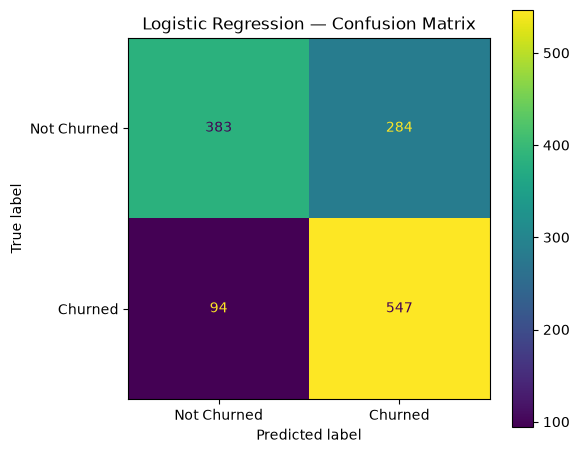

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_pred,
    ax=ax,
    display_labels=['Not Churned', 'Churned']
)
ax.set_title('Logistic Regression — Confusion Matrix')
plt.tight_layout()
plt.show()

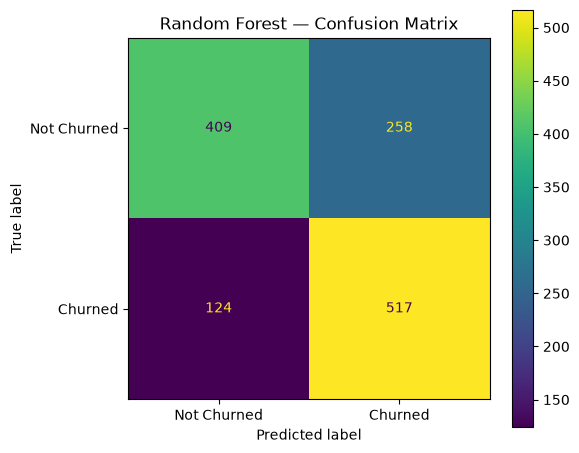

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    ax=ax,
    display_labels=['Not Churned', 'Churned']
)
ax.set_title('Random Forest — Confusion Matrix')
plt.tight_layout()
plt.show()

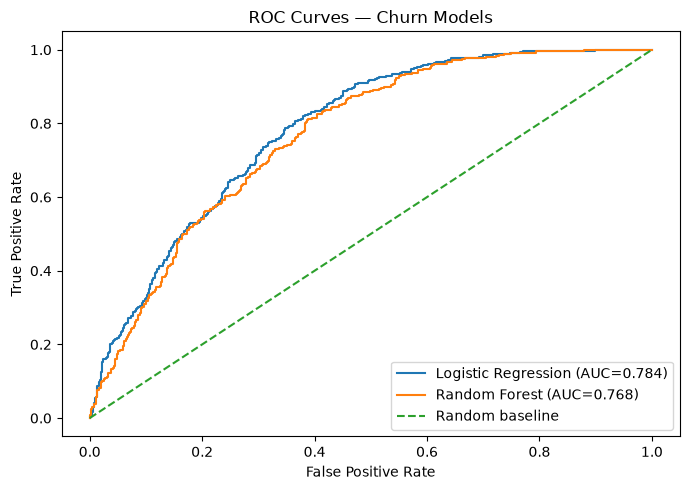

In [19]:
fpr_log, tpr_log, _ = roc_curve(y_test, logistic_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC={roc_auc_score(y_test, logistic_prob):.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC={roc_auc_score(y_test, rf_prob):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Churn Models')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Select the model

For churn intervention, recall and F1 are important because missing a genuinely churned customer can reduce the value of retention actions. ROC-AUC is also considered. The selection below ranks the models by F1 first and ROC-AUC second; the final choice should still be justified from the actual test metrics.

In [20]:
selection = results.sort_values(
    ['F1', 'ROC-AUC'],
    ascending=False
).reset_index(drop=True)

best_name = selection.loc[0, 'Model']
best_model = logistic_model if best_name == 'Logistic Regression' else rf_model

print('Selected model:', best_name)
print('\nReason: it ranks highest on the primary F1 criterion, with ROC-AUC used as the secondary criterion.')
display(selection)

Selected model: Logistic Regression

Reason: it ranks highest on the primary F1 criterion, with ROC-AUC used as the secondary criterion.


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7110,0.6582,0.8534,0.7432,0.7844
1,Random Forest,0.7080,0.6671,0.8066,0.7302,0.7685


## 10. Save the best model for Streamlit

The saved object is the complete preprocessing + model pipeline, so Streamlit can provide the eight required customer features without manually reproducing the training transformations.

In [21]:
MODEL_DIR = Path.cwd() / 'models'
MODEL_DIR.mkdir(exist_ok=True)

model_path = MODEL_DIR / 'churn_model.pkl'
joblib.dump(best_model, model_path)

print('Saved:', model_path.resolve())
print('File exists:', model_path.exists())

Saved: C:\Users\IQRA TRADERS\Desktop\hackaton\hackaton\models\churn_model.pkl
File exists: True


In [22]:
# Verify that the saved pipeline can be loaded and used for prediction.

loaded_model = joblib.load(model_path)
sample_prediction = loaded_model.predict(X_test.head(5))
sample_probability = loaded_model.predict_proba(X_test.head(5))[:, 1]

verification = X_test.head(5).copy()
verification['predicted_churn'] = sample_prediction
verification['churn_probability'] = sample_probability

verification

,total_orders,total_spending,average_order_value,days_since_last_order,return_rate,average_delivery_days,age,membership_type,predicted_churn,churn_probability
6362,6,"42,478.2544","7,079.7091",11,0.0000,3.3333,39.0000,Standard,0,0.4049
6192,3,"11,022.4763","3,674.1588",202,0.0000,3.3333,27.0000,Standard,1,0.6283
135,1,"6,420.4641","6,420.4641",369,0.0000,4.0000,18.0000,Standard,1,0.7729
2851,1,745.8831,745.8831,4,0.0000,5.0000,32.0000,Standard,1,0.5678
4438,1,640.4584,640.4584,187,0.0000,5.0000,44.0000,Standard,1,0.6783


## 11. Business interpretation template

After running the notebook, replace the placeholders below with the actual metrics from the results table.

1. **Model comparison:** The better model is `[model]` because it achieved an F1-score of `[value]` and ROC-AUC of `[value]`, compared with `[other model]`.
2. **Churn drivers:** Review the feature behavior and model results before making business claims. High `days_since_last_order` and other purchase-history variables should be interpreted from the actual dataset rather than assumed in advance.
3. **Business action:** Use the selected model to identify customers with high predicted churn probability and prioritize retention campaigns, subject to the company's campaign cost and customer-value strategy.

## Output for the Streamlit application

Saved model:

`models/churn_model.pkl`

The next Streamlit step will load this saved pipeline and create the **Churn Prediction** section with inputs for the eight churn features and a predicted churn probability.